[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_features/BA_L7_features.ipynb)

# BA_L7_features: Volatility and tail index of 33 assets

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Annualised volatility against the Hill tail index (top 5% of absolute daily log returns) of 19 cryptocurrencies and 14 traditional assets (equities, Treasuries, gold, silver, oil, FX), 2021 - October 2026 (EODHD): volatility separates the groups, the tails overlap.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['scikit-learn']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [6]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

Two of the six features of the asset-class map: annualised volatility (daily standard deviation times $\sqrt{365}$ for coins, $\sqrt{252}$
for the other assets) and the Hill estimate of the tail index on the largest 5% of $|r_t|$ (lower = heavier tail). Gold, FX and the
S&P 500 use Monday–Friday closes with repeated closes removed; US stocks and funds use adjusted closes.

Volatility: coins 57% to 132% (median 95%); traditional assets up to 37%
Hill tail index: coins 2.12 to 3.66; traditional 3.07 to 5.10; BTC 3.56, S&P 500 3.44


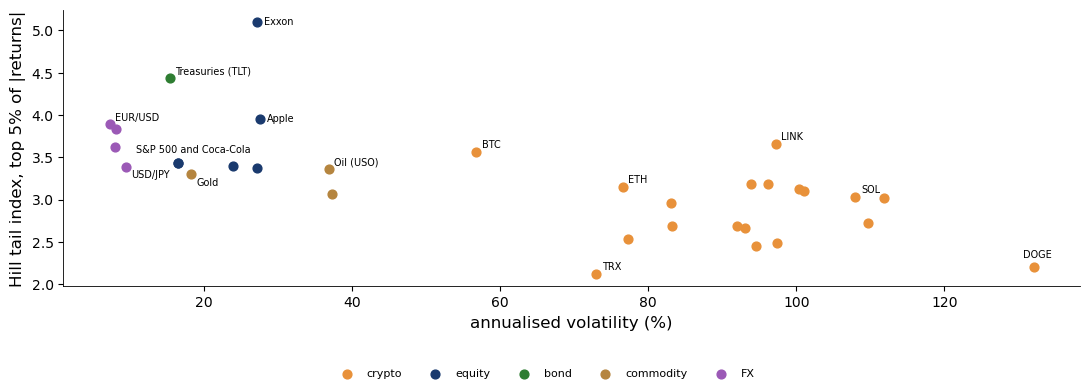

In [7]:
TRAD = {'S&P 500': 'GSPC.INDX', 'Apple': 'AAPL.US', 'Microsoft': 'MSFT.US', 'JPMorgan': 'JPM.US', 'Exxon': 'XOM.US', 'Coca-Cola': 'KO.US',
        'Treasuries (TLT)': 'TLT.US', 'Gold': 'XAUUSD.FOREX', 'Silver (SLV)': 'SLV.US', 'Oil (USO)': 'USO.US',
        'EUR/USD': 'EURUSD.FOREX', 'GBP/USD': 'GBPUSD.FOREX', 'USD/JPY': 'USDJPY.FOREX', 'USD/CHF': 'USDCHF.FOREX'}
CLS = {**{c: 'crypto' for c in COINS}, 'S&P 500': 'equity', 'Apple': 'equity', 'Microsoft': 'equity', 'JPMorgan': 'equity', 'Exxon': 'equity',
       'Coca-Cola': 'equity', 'Treasuries (TLT)': 'bond', 'Gold': 'commodity', 'Silver (SLV)': 'commodity', 'Oil (USO)': 'commodity',
       'EUR/USD': 'FX', 'GBP/USD': 'FX', 'USD/JPY': 'FX', 'USD/CHF': 'FX'}


def weekdays(s, sym):
    """Gold, FX and indices: Monday-Friday closes, repeated closes removed."""
    if sym.endswith(('.FOREX', '.INDX')):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def hill(x, frac=0.05):
    """Hill estimator of the tail index from the largest frac of |x|."""
    a = np.sort(np.abs(x))[::-1]
    k = int(frac * len(a))
    return 1 / np.mean(np.log(a[:k] / a[k]))


series = {**{c: P[c] for c in COINS}, **{k: weekdays(px(v), v).loc['2021-01-01':] for k, v in TRAD.items()}}
F = pd.DataFrame({k: dict(vol=(100 * np.log(s).diff().dropna()).std() * np.sqrt(365 if CLS[k] == 'crypto' else 252),
                          tail_index=hill((100 * np.log(s).diff().dropna()).values)) for k, s in series.items()}).T
trad = [k for k in F.index if CLS[k] != 'crypto']
print(f"Volatility: coins {F.loc[COINS, 'vol'].min():.0f}% to {F.loc[COINS, 'vol'].max():.0f}% (median {F.loc[COINS, 'vol'].median():.0f}%); "
      f"traditional assets up to {F.loc[trad, 'vol'].max():.0f}%")
print(f"Hill tail index: coins {F.loc[COINS, 'tail_index'].min():.2f} to {F.loc[COINS, 'tail_index'].max():.2f}; "
      f"traditional {F.loc[trad, 'tail_index'].min():.2f} to {F.loc[trad, 'tail_index'].max():.2f}; BTC {F.loc['BTC', 'tail_index']:.2f}, S&P 500 {F.loc['S&P 500', 'tail_index']:.2f}")
fig, ax = plt.subplots(figsize=(11, 3.9))
for cl, col in {'crypto': BTC, 'equity': BLUE, 'bond': GREEN, 'commodity': GOLD, 'FX': ETH}.items():
    m = [CLS[k] == cl for k in F.index]
    ax.scatter(F['vol'][m], F['tail_index'][m], color=col, s=40, label=cl)
LBL = {'BTC': (4, 3), 'ETH': (4, 3), 'DOGE': (-8, 7), 'SOL': (4, 3), 'TRX': (4, 3), 'LINK': (4, 3), 'S&P 500': (-30, 7),
       'Gold': (4, -8), 'Oil (USO)': (4, 3), 'EUR/USD': (4, 3), 'USD/JPY': (4, -8), 'Treasuries (TLT)': (4, 3), 'Exxon': (5, -2), 'Apple': (5, -2)}
for k, off in LBL.items():
    ax.annotate('S&P 500 and Coca-Cola' if k == 'S&P 500' else k, (F.loc[k, 'vol'], F.loc[k, 'tail_index']), fontsize=7, xytext=off, textcoords='offset points')
ax.set_xlabel('annualised volatility (%)'); ax.set_ylabel('Hill tail index, top 5% of |returns|')
slide_fig(fig, 'ba_l7_features', 0.1, ncol=5)

**How to read it.** Volatility alone separates every coin from every traditional asset; the tail index does not: the ranges overlap, and
Bitcoin's tail is lighter than that of the S&P 500 in this sample.